# Etapa 2 - Modelo Predictivo Random Forest Regressor

## Iteración sobre la Etapa 1

La Etapa 1 diagnosticó que el principal problema es una captura de datos no estandarizada, con decisiones que parecen apoyarse en la intuición, y propuso abrir un área de analítica comercial, a abordar después de ordenar la captura. Esta etapa hace evolucionar el proyecto de la descripción a la predicción: se reutiliza como piloto la misma base de análisis (bloque A, pagos con tarjeta), se incorpora una variable objetivo de rentabilidad, se entrena y optimiza un `RandomForestRegressor` contrastado con un modelo base, y el resultado se entrega al usuario en una aplicación web. Como los problemas de captura siguen vigentes, los resultados deben leerse como una primera versión y no como pronósticos definitivos.

## Problema de negocio

- **Organización:** cafetería.
- **Usuario objetivo:** encargado de compras y abastecimiento.
- **Necesidad:** decidir qué cafés priorizar al abastecerse con apoyo en el historial de ventas y no solo en su experiencia.
- **Pregunta de negocio:** *¿Qué tipo de café tendrá la mayor rentabilidad esperada durante el próximo mes considerando el comportamiento histórico de ventas?*

## Carga de librerías

In [1]:
import json
import os
import time
from collections import Counter

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, train_test_split
from sklearn.preprocessing import OneHotEncoder   # requiere scikit-learn >= 1.2

pd.set_option("display.width", 130)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

def es(valor, decimales=0, porcentaje=False):
    """Formato numérico en español: 1.234,5 y 12,3 %."""
    if porcentaje:
        valor *= 100
    texto = f"{valor:,.{decimales}f}".replace(",", "_").replace(".", ",").replace("_", ".")
    return texto + (" %" if porcentaje else "")


SEMILLA = 42
HORIZONTE_DIAS = 30    # "próximo mes"
PASO_DIAS = 7          # una fecha de corte por semana
RUTA_MODELO = "modelo"

## Carga de datos

In [2]:
# El archivo debe estar en la misma carpeta que el notebook
df = pd.read_csv("dataset_cafeteria.csv")
COLUMNAS = list(df.columns)
print(f"{df.shape[0]:,} filas x {df.shape[1]} columnas")

3,898 filas x 6 columnas


## Exploración inicial

In [3]:
print(f"Período: {df['date'].min()} a {df['date'].max()}")
display(df.dtypes.to_frame("tipo").T)
display(df.isna().sum().to_frame("nulos").T)
display(df.head(3))

Período: 2024-03-01 a 2025-03-23


,date,datetime,cash_type,card,money,coffee_name
tipo,str,str,str,str,float64,str


,date,datetime,cash_type,card,money,coffee_name
nulos,0,0,0,351,0,0


,date,datetime,cash_type,card,money,coffee_name
0,2024-03-01,10:15,card,ANON-0000-0000-0001,38.7,Latte
1,2024-03-01,12:19,card,ANON-0000-0000-0002,38.7,Hot Chocolate
2,2024-03-01,12:20,card,ANON-0000-0000-0002,38.7,Hot Chocolate


Solo `money` es numérica y no existen columnas de cantidad, costo ni stock; `datetime` contiene únicamente la hora. La estrategia se adapta a lo disponible: producto (`coffee_name`), precio (`money`), medio de pago, fecha y hora. Cada fila es una unidad vendida (Etapa 1).

## Preparación de datos

In [4]:
def preparar_ventas(datos):
    """Base de análisis de la Etapa 1: bloque A (antes del quiebre de fechas) y solo pagos con tarjeta."""
    v = datos.copy()
    v["ts"] = pd.to_datetime(v["date"] + " " + v["datetime"])
    retrocesos = (v["ts"].diff() < pd.Timedelta(0)).to_numpy()
    if retrocesos.any():                      # el bloque B reinicia la cronología
        v = v.iloc[: retrocesos.argmax()]
    v = v[v["cash_type"] == "card"].copy()
    v["fecha"] = v["ts"].dt.normalize()
    v["noche"] = (v["ts"].dt.hour >= 18).astype(int)
    v["finde"] = (v["ts"].dt.dayofweek >= 5).astype(int)
    v["cantidad"] = 1                         # cada fila es una unidad vendida
    return v


ventas = preparar_ventas(df)
print(f"Base de análisis: {len(ventas):,} de {len(df):,} filas ({ventas['fecha'].min().date()} a {ventas['fecha'].max().date()})")
print(f"Nulos: {df.isna().sum().sum()} en el archivo -> {ventas[COLUMNAS].isna().sum().sum()} en la base")

duplicadas = ventas.duplicated(subset=COLUMNAS)
sin_dup = ventas.loc[~duplicadas, "money"].sum()
print(f"Duplicados exactos: {duplicadas.sum()} ({duplicadas.mean():.2%}) | efecto en el ingreso total si se eliminan: {1 - sin_dup / ventas['money'].sum():.2%}")

Base de análisis: 3,547 de 3,898 filas (2024-03-01 a 2025-03-23)
Nulos: 351 en el archivo -> 0 en la base
Duplicados exactos: 13 (0.37%) | efecto en el ingreso total si se eliminan: 0.36%


- **Nulos:** los 351 nulos de `card` corresponden a pagos en efectivo y al bloque B, que quedan fuera de la base por los motivos de la Etapa 1 (bloque B superpuesto con A y sin ID; efectivo sin registros entre julio de 2024 y enero de 2025). La base no tiene nulos.
- **Duplicados:** se conservan. Sin ID de transacción no es posible distinguirlos de dos compras iguales en el mismo minuto (Etapa 1) y su efecto sobre el ingreso es marginal.

In [5]:
def armar_panel_diario(v):
    """Tablas día x café (con 0 en los días sin ventas) para compras, ingresos, precio y composición horaria."""
    calendario = pd.date_range(v["fecha"].min(), v["fecha"].max())
    cafes = sorted(v["coffee_name"].unique())
    indice = pd.MultiIndex.from_product([calendario, cafes], names=["fecha", "cafe"])
    diario = (v.groupby(["fecha", "coffee_name"])
                .agg(compras=("cantidad", "sum"), ingresos=("money", "sum"), precio=("money", "mean"),
                     noche=("noche", "sum"), finde=("finde", "sum")))
    diario.index.names = ["fecha", "cafe"]
    diario = diario.reindex(indice)
    cantidades = ["compras", "ingresos", "noche", "finde"]
    diario[cantidades] = diario[cantidades].fillna(0)
    diario["precio"] = diario.groupby("cafe")["precio"].ffill()      # último precio observado
    return {campo: diario[campo].unstack() for campo in diario.columns}


panel = armar_panel_diario(ventas)
CAFES = list(panel["compras"].columns)

# Codificación de la variable categórica (café)
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(pd.DataFrame({"cafe": CAFES}))
print(f"{panel['compras'].shape[0]} días x {len(CAFES)} cafés | categorías codificadas: {list(encoder.get_feature_names_out())}")

388 días x 8 cafés | categorías codificadas: ['cafe_Americano', 'cafe_Americano with Milk', 'cafe_Cappuccino', 'cafe_Cocoa', 'cafe_Cortado', 'cafe_Espresso', 'cafe_Hot Chocolate', 'cafe_Latte']


Los 7 días sin registros de la Etapa 1 se tratan como días sin ventas. El café se codifica con *one-hot* porque los árboles no interpretan texto y no existe un orden entre productos.

## Ingeniería de características

In [6]:
VARIABLES_NUMERICAS = ["compras_7d", "compras_14d", "compras_30d", "ingresos_7d", "ingresos_30d",
                       "precio_actual", "tendencia", "participacion_30d", "pct_noche_30d", "pct_finde_30d"]


def armar_tabla_cafe(panel, fecha_ref):
    """Una fila por café, calculada SOLO con ventas hasta `fecha_ref` (evita la fuga de datos)."""
    fecha_ref = pd.Timestamp(fecha_ref)
    ventana = lambda campo, dias: panel[campo].loc[fecha_ref - pd.Timedelta(days=dias - 1): fecha_ref]

    t = pd.DataFrame(index=panel["compras"].columns)
    for dias in (7, 14, 30):
        t[f"compras_{dias}d"] = ventana("compras", dias).sum()
    t["ingresos_7d"] = ventana("ingresos", 7).sum()
    t["ingresos_30d"] = ventana("ingresos", 30).sum()
    t["precio_actual"] = panel["precio"].loc[fecha_ref]
    ritmo_mensual = (t["compras_30d"] * 7 / 30).replace(0, np.nan)
    t["tendencia"] = (t["compras_7d"] / ritmo_mensual).fillna(1.0)       # > 1: la última semana acelera
    t["participacion_30d"] = t["compras_30d"] / t["compras_30d"].sum()
    compras_30d = t["compras_30d"].replace(0, np.nan)
    t["pct_noche_30d"] = (ventana("noche", 30).sum() / compras_30d).fillna(0)
    t["pct_finde_30d"] = (ventana("finde", 30).sum() / compras_30d).fillna(0)
    return t.rename_axis("cafe").reset_index()


def armar_matriz(tabla, encoder):
    """Variables numéricas + café codificado, en el orden que espera el modelo."""
    codificado = pd.DataFrame(encoder.transform(tabla[["cafe"]]),
                              columns=encoder.get_feature_names_out(["cafe"]), index=tabla.index)
    return pd.concat([tabla[VARIABLES_NUMERICAS], codificado], axis=1)


armar_tabla_cafe(panel, panel["ingresos"].index.max()).round(2)

,cafe,compras_7d,compras_14d,compras_30d,ingresos_7d,ingresos_30d,precio_actual,tendencia,participacion_30d,pct_noche_30d,pct_finde_30d
0,Americano,35.0,64.0,130.0,908.60,3374.80,25.96,1.15,0.31,0.05,0.15
1,Americano with Milk,17.0,31.0,73.0,524.62,2252.78,30.86,1.00,0.17,0.11,0.30
2,Cappuccino,13.0,26.0,54.0,464.88,1931.04,35.76,1.03,0.13,0.19,0.20
3,Cocoa,11.0,19.0,43.0,393.36,1537.68,35.76,1.10,0.10,0.33,0.14
4,Cortado,2.0,2.0,3.0,51.92,77.88,25.96,2.86,0.01,0.33,0.00
5,Espresso,5.0,7.0,14.0,105.30,294.84,21.06,1.53,0.03,0.14,0.21
6,Hot Chocolate,6.0,13.0,28.0,214.56,1001.28,35.76,0.92,0.07,0.07,0.11
7,Latte,20.0,41.0,73.0,715.20,2610.48,35.76,1.17,0.17,0.22,0.08


| Grupo | Variables | Para qué sirven |
|---|---|---|
| Nivel de ventas | `compras_7d/14d/30d`, `ingresos_7d/30d` | Punto de partida de cada café |
| Precio | `precio_actual` | El precio cambia por períodos (Etapa 1) y determina el ingreso por compra |
| Impulso | `tendencia`, `participacion_30d` | Si el café acelera y cuánto pesa frente al resto |
| Temporales | `pct_noche_30d`, `pct_finde_30d` | Mezcla horaria y semanal de sus compras |
| Categórica | `cafe` (one-hot) | Identidad del producto |

No se incluye el mes del año: con un solo ciclo de 13 meses el modelo no puede aprender estacionalidad y solo memorizaría el período.

## Variable objetivo

**Rentabilidad = Σ (precio × cantidad)** de cada café durante los 30 días posteriores a una fecha de corte. Como cada fila es una unidad, la cantidad es 1 y equivale a la suma de `money`. El dataset no tiene costos ni márgenes: es un **ingreso bruto** que aproxima la rentabilidad, no una utilidad neta.

In [7]:
def calcular_objetivo(panel, fecha_ref):
    """Rentabilidad de cada café en los HORIZONTE_DIAS posteriores a `fecha_ref`."""
    desde = pd.Timestamp(fecha_ref) + pd.Timedelta(days=1)
    return panel["ingresos"].loc[desde: desde + pd.Timedelta(days=HORIZONTE_DIAS - 1)].sum()


def armar_dataset(panel, fechas):
    """Una fila por café y fecha de corte: características del pasado y rentabilidad del mes siguiente."""
    filas = []
    for fecha in fechas:
        t = armar_tabla_cafe(panel, fecha)
        t["fecha_ref"] = fecha
        t["y"] = t["cafe"].map(calcular_objetivo(panel, fecha))
        filas.append(t)
    return pd.concat(filas, ignore_index=True).sort_values(["fecha_ref", "cafe"]).reset_index(drop=True)


# Fechas de corte: con 30 días de historia previa y 30 días de futuro observado
dias = panel["ingresos"].index
fechas_corte = pd.date_range(dias.min() + pd.Timedelta(days=29), dias.max() - pd.Timedelta(days=HORIZONTE_DIAS),
                             freq=f"{PASO_DIAS}D")
dataset = armar_dataset(panel, fechas_corte)
X = armar_matriz(dataset, encoder)
y = dataset["y"]

print(f"{len(fechas_corte)} fechas de corte x {len(CAFES)} cafés = {len(dataset)} filas | nulos: {int(dataset.isna().sum().sum())}")
display(dataset.groupby("cafe")["y"].agg(media="mean", minimo="min", maximo="max").round(0).sort_values("media", ascending=False))

47 fechas de corte x 8 cafés = 376 filas | nulos: 0


,media,minimo,maximo
cafe,,,
Latte,2152.0,954.0,4291.0
Americano with Milk,2015.0,1136.0,2971.0
Cappuccino,1394.0,822.0,2188.0
Americano,1031.0,391.0,3660.0
Hot Chocolate,768.0,131.0,2003.0
Cocoa,665.0,108.0,2110.0
Cortado,577.0,26.0,1031.0
Espresso,201.0,24.0,358.0


## Partición de datos

La partición es **cronológica** (`train_test_split` sin mezclar): se entrena con el pasado y se evalúa con el período más reciente. Como la rentabilidad mira 30 días hacia adelante, se descarta de entrenamiento el último mes previo a la prueba para que ningún objetivo de entrenamiento se superponga con el período evaluado.

In [8]:
fechas = dataset["fecha_ref"].drop_duplicates().sort_values().reset_index(drop=True)
f_train, f_test = train_test_split(fechas, test_size=0.20, shuffle=False)
f_train = f_train[f_train <= f_test.iloc[0] - pd.Timedelta(days=HORIZONTE_DIAS)]    # separación de 30 días

es_train, es_test = dataset["fecha_ref"].isin(f_train), dataset["fecha_ref"].isin(f_test)
X_train, y_train = X[es_train], y[es_train]
X_test, y_test = X[es_test], y[es_test]
test = dataset[es_test].copy()

print(f"Entrenamiento: {X_train.shape} ({f_train.min().date()} a {f_train.max().date()})")
print(f"Prueba:        {X_test.shape} ({f_test.min().date()} a {f_test.max().date()})")

Entrenamiento: (264, 18) (2024-03-30 a 2024-11-09)
Prueba:        (80, 18) (2024-12-14 a 2025-02-15)


## Optimización del Random Forest

Búsqueda exhaustiva (`GridSearchCV`) sobre `n_estimators`, `max_depth`, `min_samples_split` y `min_samples_leaf`, minimizando el MAE. La validación cruzada también es temporal (`TimeSeriesSplit`, con separación entre pliegues) para no mirar el futuro.

In [9]:
PARAMETROS = {
    "n_estimators": [100, 300],
    "max_depth": [4, 8, None],
    "min_samples_split": [2, 10],
    "min_samples_leaf": [1, 5, 10],
}
separacion = int(np.ceil(HORIZONTE_DIAS / PASO_DIAS)) * len(CAFES)    # filas equivalentes a 30 días
busqueda = GridSearchCV(RandomForestRegressor(random_state=SEMILLA, n_jobs=-1), PARAMETROS,
                        cv=TimeSeriesSplit(n_splits=4, gap=separacion), scoring="neg_mean_absolute_error")
busqueda.fit(X_train, y_train)

resultados_cv = (pd.DataFrame(busqueda.cv_results_)
                 .assign(mae_cv=lambda t: -t["mean_test_score"])
                 .sort_values("mae_cv")[["param_n_estimators", "param_max_depth", "param_min_samples_split",
                                         "param_min_samples_leaf", "mae_cv"]]
                 .head(5).round(1))
print(f"Combinaciones evaluadas: {len(busqueda.cv_results_['params'])}")
print("Mejor configuración:", busqueda.best_params_)
display(resultados_cv)

Combinaciones evaluadas: 36
Mejor configuración: {'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}


,param_n_estimators,param_max_depth,param_min_samples_split,param_min_samples_leaf,mae_cv
0,100,4,2,1,427.9
24,100,None,2,1,431.1
25,300,None,2,1,431.4
1,300,4,2,1,431.7
12,100,8,2,1,432.3


## Entrenamiento

In [10]:
mejor_rf = busqueda.best_estimator_            # ya reentrenado con todo el conjunto de entrenamiento
pred_train = mejor_rf.predict(X_train)
pred_test = mejor_rf.predict(X_test)
test["pred_rf"] = pred_test
test["pred_base"] = test["ingresos_30d"]       # modelo base: repetir lo ganado en los 30 días anteriores

print(f"MAE de validación cruzada (mejor configuración): {-busqueda.best_score_:,.1f}")
print(f"Predicciones generadas: {len(pred_test)} filas de prueba")

MAE de validación cruzada (mejor configuración): 427.9
Predicciones generadas: 80 filas de prueba


El **modelo base** no aprende nada: asume que cada café repetirá la rentabilidad de los 30 días anteriores. Representa una decisión basada en lo ocurrido el mes pasado y sirve para medir si el Random Forest aporta algo más. El modelo oficial es únicamente `RandomForestRegressor`.

## Evaluación del modelo

,MAE,RMSE,R²
Random Forest (prueba),475.36,713.29,0.30
Modelo base (prueba),492.42,735.25,0.26
Random Forest (entrenamiento),218.95,292.29,0.88


,Spearman,Top 1,Top 3
Random Forest,0.77,0.3,0.7
Modelo base,0.70,0.2,0.7


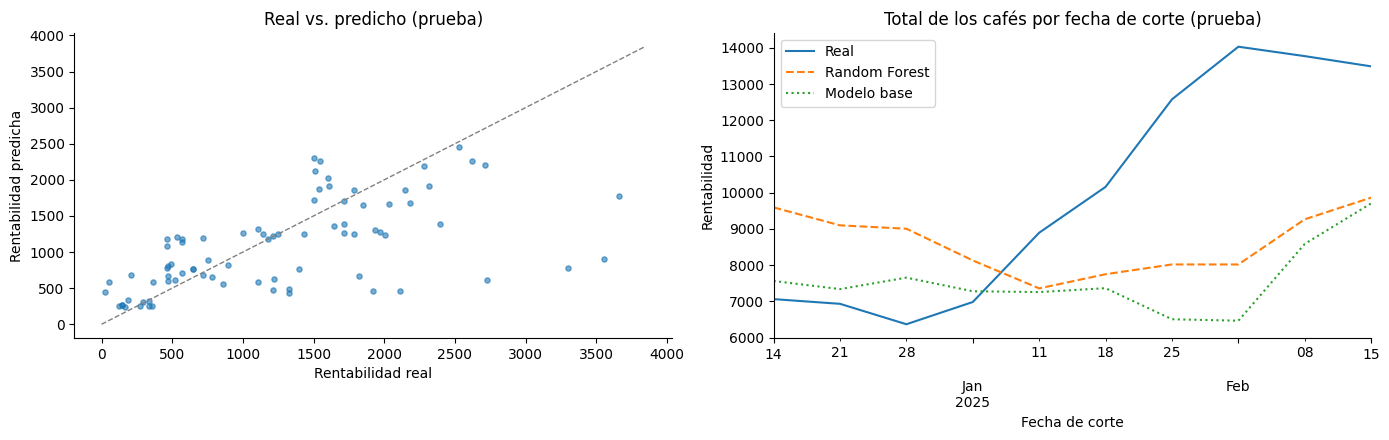

In [11]:
def calcular_metricas(real, pred):
    return {"MAE": mean_absolute_error(real, pred),
            "RMSE": np.sqrt(mean_squared_error(real, pred)),
            "R²": r2_score(real, pred)}


def evaluar_ranking(datos, columna_pred):
    """Por fecha de corte: ¿el modelo ordena los cafés como ocurrió en la realidad?"""
    spearman, acierta_1, acierta_3 = [], [], []
    for _, g in datos.groupby("fecha_ref"):
        orden = g.sort_values(columna_pred, ascending=False)["cafe"].tolist()
        mejor_real = g.loc[g["y"].idxmax(), "cafe"]
        spearman.append(spearmanr(g[columna_pred], g["y"])[0])
        acierta_1.append(orden[0] == mejor_real)
        acierta_3.append(mejor_real in orden[:3])
    return {"Spearman": np.nanmean(spearman), "Top 1": np.mean(acierta_1), "Top 3": np.mean(acierta_3)}


m_rf = calcular_metricas(y_test, test["pred_rf"])
m_base = calcular_metricas(y_test, test["pred_base"])
m_train = calcular_metricas(y_train, pred_train)
rk_rf = evaluar_ranking(test, "pred_rf")
rk_base = evaluar_ranking(test, "pred_base")

tabla_metricas = pd.DataFrame({"Random Forest (prueba)": m_rf, "Modelo base (prueba)": m_base,
                               "Random Forest (entrenamiento)": m_train}).T
display(tabla_metricas.round(2))
display(pd.DataFrame({"Random Forest": rk_rf, "Modelo base": rk_base}).T.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(test["y"], test["pred_rf"], s=14, alpha=.6)
limite = [0, max(test["y"].max(), test["pred_rf"].max()) * 1.05]
axes[0].plot(limite, limite, color="gray", ls="--", lw=1)
axes[0].set(title="Real vs. predicho (prueba)", xlabel="Rentabilidad real", ylabel="Rentabilidad predicha")

por_fecha = test.groupby("fecha_ref")[["y", "pred_rf", "pred_base"]].sum()
por_fecha.plot(ax=axes[1], style=["-", "--", ":"])
axes[1].legend(["Real", "Random Forest", "Modelo base"])
axes[1].set(title="Total de los cafés por fecha de corte (prueba)", xlabel="Fecha de corte", ylabel="Rentabilidad")
plt.tight_layout(); plt.show()

In [12]:
mejora_mae = 1 - m_rf["MAE"] / m_base["MAE"]
sesgo = (test["pred_rf"] - test["y"]).mean()
display(Markdown(f'''
- **Error típico (MAE):** {es(m_rf["MAE"])} unidades monetarias por café y mes ({es(m_rf["MAE"] / test["y"].mean(), 0, True)} de la rentabilidad media observada en prueba). El modelo base tiene {es(m_base["MAE"])}: el Random Forest {"reduce" if mejora_mae > 0 else "aumenta"} el error en {es(abs(mejora_mae), 1, True)}.
- **R²:** {es(m_rf["R²"], 2)} frente a {es(m_base["R²"], 2)} del modelo base. Es un ajuste moderado: la prueba abarca solo {len(f_test)} fechas de corte con ventanas superpuestas y hay {len(dias)} días de historia, por lo que la comparación con el modelo base es indicativa.
- **Ordenamiento de cafés:** correlación de Spearman media de {es(rk_rf["Spearman"], 2)} y el café realmente más rentable quedó entre los 3 primeros del modelo en {es(rk_rf["Top 3"], 0, True)} de las fechas de corte (modelo base: {es(rk_base["Top 3"], 0, True)}).
- **Generalización:** R² de {es(m_train["R²"], 2)} en entrenamiento frente a {es(m_rf["R²"], 2)} en prueba: el modelo aprende más del pasado que lo que logra trasladar al período más reciente, donde además {"subestima" if sesgo < 0 else "sobreestima"} en promedio {es(abs(sesgo))} unidades por café.
'''))


- **Error típico (MAE):** 475 unidades monetarias por café y mes (38 % de la rentabilidad media observada en prueba). El modelo base tiene 492: el Random Forest reduce el error en 3,5 %.
- **R²:** 0,30 frente a 0,26 del modelo base. Es un ajuste moderado: la prueba abarca solo 10 fechas de corte con ventanas superpuestas y hay 388 días de historia, por lo que la comparación con el modelo base es indicativa.
- **Ordenamiento de cafés:** correlación de Spearman media de 0,77 y el café realmente más rentable quedó entre los 3 primeros del modelo en 70 % de las fechas de corte (modelo base: 70 %).
- **Generalización:** R² de 0,88 en entrenamiento frente a 0,30 en prueba: el modelo aprende más del pasado que lo que logra trasladar al período más reciente, donde además subestima en promedio 177 unidades por café.


## Importancia de variables

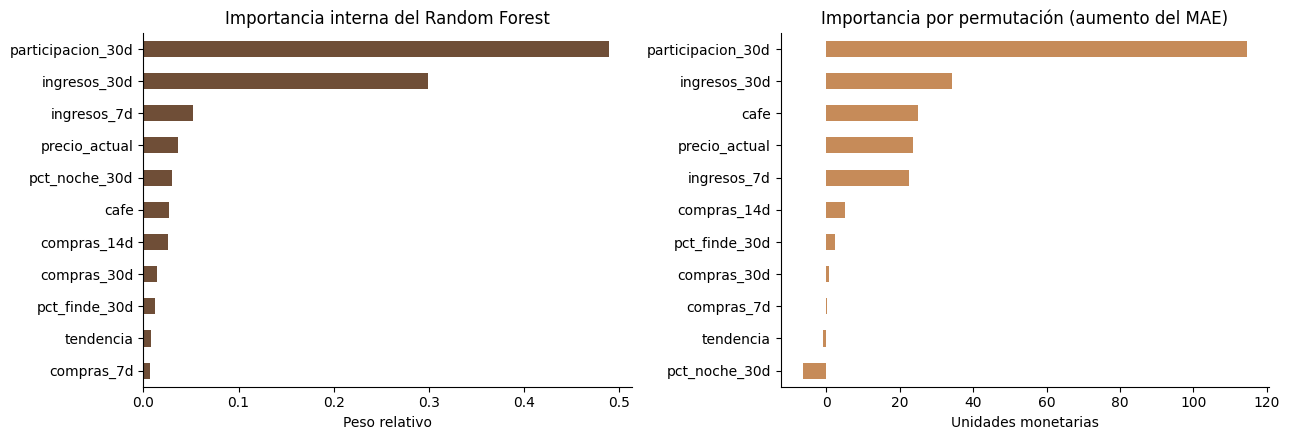

In [13]:
def importancia_permutacion(modelo, X, y, grupos, repeticiones=20):
    """Aumento del MAE al desordenar cada variable (las columnas del café se mezclan juntas)."""
    rng = np.random.default_rng(SEMILLA)
    mae_inicial = mean_absolute_error(y, modelo.predict(X))
    resultado = {}
    for nombre, columnas in grupos.items():
        aumentos = []
        for _ in range(repeticiones):
            X_mezclado = X.copy()
            X_mezclado[columnas] = X_mezclado[columnas].to_numpy()[rng.permutation(len(X))]
            aumentos.append(mean_absolute_error(y, modelo.predict(X_mezclado)) - mae_inicial)
        resultado[nombre] = np.mean(aumentos)
    return pd.Series(resultado)


columnas_cafe = [c for c in X.columns if c.startswith("cafe_")]
GRUPOS = {**{v: [v] for v in VARIABLES_NUMERICAS}, "cafe": columnas_cafe}

imp_interna = (pd.Series(mejor_rf.feature_importances_, index=X.columns)
               .groupby(lambda c: "cafe" if c.startswith("cafe_") else c).sum().sort_values(ascending=False))
imp_perm = importancia_permutacion(mejor_rf, X_test, y_test, GRUPOS).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
imp_interna.sort_values().plot.barh(ax=axes[0], color="#6f4e37")
axes[0].set(title="Importancia interna del Random Forest", xlabel="Peso relativo")
imp_perm.sort_values().plot.barh(ax=axes[1], color="#c68b59")
axes[1].set(title="Importancia por permutación (aumento del MAE)", xlabel="Unidades monetarias")
plt.tight_layout(); plt.show()

In [14]:
top_interna = ", ".join(f"`{v}` ({es(p, 0, True)})" for v, p in imp_interna.head(3).items())
top_perm = ", ".join(f"`{v}`" for v in imp_perm.head(3).index)
display(Markdown(f'''
Las variables más influyentes según el propio bosque son {top_interna}; por permutación (efecto real sobre el error en prueba) destacan {top_perm}. Son señales que usa el modelo para predecir, no causas de la rentabilidad.
'''))


Las variables más influyentes según el propio bosque son `participacion_30d` (49 %), `ingresos_30d` (30 %), `ingresos_7d` (5 %); por permutación (efecto real sobre el error en prueba) destacan `participacion_30d`, `ingresos_30d`, `cafe`. Son señales que usa el modelo para predecir, no causas de la rentabilidad.


## Predicción de negocio

Se reentrena el mejor Random Forest con **todas** las fechas de corte disponibles para aprovechar los meses más recientes, y se predice a partir del último día de datos. Solo este modelo genera las predicciones.

In [15]:
modelo_final = RandomForestRegressor(**busqueda.best_params_, random_state=SEMILLA, n_jobs=-1).fit(X, y)

fecha_fin = panel["ingresos"].index.max()
tabla_hoy = armar_tabla_cafe(panel, fecha_fin)
X_hoy = armar_matriz(tabla_hoy, encoder)

# Dispersión entre los árboles del bosque (referencia de incertidumbre, no es un intervalo estadístico)
por_arbol = np.array([arbol.predict(X_hoy.to_numpy()) for arbol in modelo_final.estimators_])
tabla_hoy["rentabilidad_estimada"] = modelo_final.predict(X_hoy)
tabla_hoy["p10"], tabla_hoy["p90"] = np.percentile(por_arbol, [10, 90], axis=0)
tabla_hoy["ultimos_30d"] = tabla_hoy["ingresos_30d"]
tabla_hoy["variacion_pct"] = tabla_hoy["rentabilidad_estimada"] / tabla_hoy["ultimos_30d"] - 1
tabla_hoy["peso_total"] = tabla_hoy["rentabilidad_estimada"] / tabla_hoy["rentabilidad_estimada"].sum()

ranking = tabla_hoy.sort_values("rentabilidad_estimada", ascending=False).reset_index(drop=True)
ranking.index = ranking.index + 1
ranking.index.name = "puesto"

inicio, fin = fecha_fin + pd.Timedelta(days=1), fecha_fin + pd.Timedelta(days=HORIZONTE_DIAS)
print(f"Horizonte de la predicción: {inicio.date()} a {fin.date()}")
display(ranking[["cafe", "rentabilidad_estimada", "peso_total", "p10", "p90", "ultimos_30d", "variacion_pct"]]
        .rename(columns={"rentabilidad_estimada": "estimada", "peso_total": "% del total", "ultimos_30d": "últimos 30 días",
                         "variacion_pct": "variación"}).round(2))

total_proyectado, total_previo = ranking["rentabilidad_estimada"].sum(), ranking["ultimos_30d"].sum()
variacion_total = total_proyectado / total_previo - 1
print(f"Total proyectado: {total_proyectado:,.0f} | últimos 30 días: {total_previo:,.0f} ({variacion_total:+.0%})")
for _, r in ranking[ranking["compras_30d"] < 10].iterrows():
    print(f"Nota: {r['cafe']} tuvo solo {r['compras_30d']:.0f} compras en los últimos 30 días; su variación ({r['variacion_pct']:+.0%}) parte de una base muy baja.")

mas_rentable = ranking.iloc[0]
control = mejor_rf.predict(X_hoy)
print(f"Café más rentable esperado: {mas_rentable['cafe']} | {mas_rentable['rentabilidad_estimada']:,.0f} unidades monetarias")
print("El modelo entrenado solo con el período de entrenamiento coincide en el puesto 1:",
      tabla_hoy.loc[control.argmax(), "cafe"] == mas_rentable["cafe"])

Horizonte de la predicción: 2025-03-24 a 2025-04-22


,cafe,estimada,% del total,p10,p90,últimos 30 días,variación
puesto,,,,,,,
1,Americano,2810.48,0.25,2073.74,3607.56,3374.80,-0.17
2,Latte,2339.97,0.21,1351.16,3556.52,2610.48,-0.10
3,Americano with Milk,1569.06,0.14,1002.40,1995.64,2252.78,-0.30
4,Cappuccino,1353.68,0.12,947.79,1875.01,1931.04,-0.30
5,Cocoa,1186.80,0.11,886.80,1517.58,1537.68,-0.23
6,Hot Chocolate,979.46,0.09,667.83,1251.32,1001.28,-0.02
7,Cortado,581.73,0.05,289.68,815.65,77.88,6.47
8,Espresso,278.43,0.03,147.70,636.69,294.84,-0.06


Total proyectado: 11,100 | últimos 30 días: 13,081 (-15%)
Nota: Cortado tuvo solo 3 compras en los últimos 30 días; su variación (+647%) parte de una base muy baja.
Café más rentable esperado: Americano | 2,810 unidades monetarias
El modelo entrenado solo con el período de entrenamiento coincide en el puesto 1: True


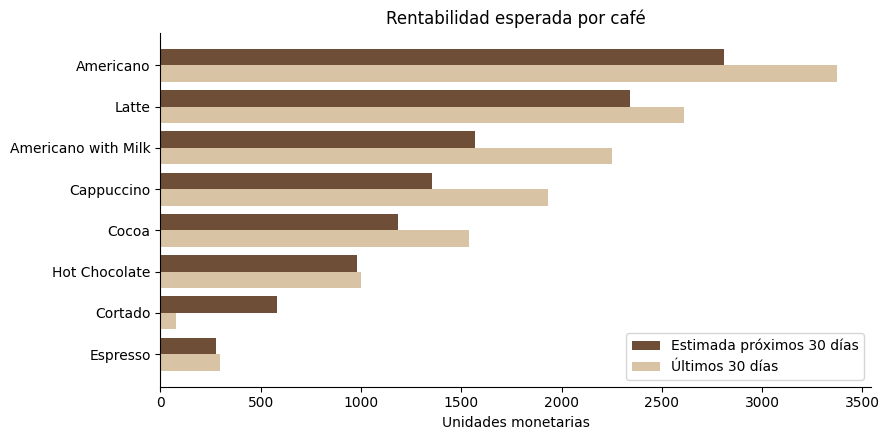

,participacion_30d,ingresos_30d,ingresos_7d,compras_14d,cafe
importancia (modelo final),0.376,0.34,0.065,0.064,0.049


,cafe,precio_actual,compras_30d,tendencia,participacion_30d,pct_noche_30d
puesto,,,,,,
1,Americano,25.96,130.0,1.15,0.31,0.05
2,Latte,35.76,73.0,1.17,0.17,0.22
3,Americano with Milk,30.86,73.0,1.00,0.17,0.11
4,Cappuccino,35.76,54.0,1.03,0.13,0.19
5,Cocoa,35.76,43.0,1.10,0.10,0.33
6,Hot Chocolate,35.76,28.0,0.92,0.07,0.07
7,Cortado,25.96,3.0,2.86,0.01,0.33
8,Espresso,21.06,14.0,1.53,0.03,0.14


In [16]:
fig, ax = plt.subplots(figsize=(9, 4.5))
orden = ranking.iloc[::-1]
posicion = np.arange(len(orden))
ax.barh(posicion + .2, orden["rentabilidad_estimada"], height=.4, color="#6f4e37", label="Estimada próximos 30 días")
ax.barh(posicion - .2, orden["ultimos_30d"], height=.4, color="#d9c3a5", label="Últimos 30 días")
ax.set_yticks(posicion)
ax.set_yticklabels(orden["cafe"])
ax.set(title="Rentabilidad esperada por café", xlabel="Unidades monetarias")
ax.legend()
plt.tight_layout(); plt.show()

# Variables que explican la predicción: peso global y valores de cada café
imp_final = (pd.Series(modelo_final.feature_importances_, index=X.columns)
             .groupby(lambda c: "cafe" if c.startswith("cafe_") else c).sum().sort_values(ascending=False))
display(imp_final.head(5).round(3).to_frame("importancia (modelo final)").T)
display(ranking[["cafe", "precio_actual", "compras_30d", "tendencia", "participacion_30d", "pct_noche_30d"]].round(2))

## Conclusiones

In [17]:
segundo, tercero = ranking.iloc[1], ranking.iloc[2]
brecha = mas_rentable["rentabilidad_estimada"] - segundo["rentabilidad_estimada"]
peso_top3 = ranking["peso_total"].head(3).sum()
variables_clave = ", ".join(f"`{v}`" for v in imp_final.head(2).index)
holgura = brecha / m_rf["MAE"]
solapan = mas_rentable["p10"] < segundo["p90"] and segundo["p10"] < mas_rentable["p90"]
lectura = "líder más probable dentro de un grupo prioritario y no un ganador seguro" if (solapan or holgura < 2) else "líder claro"
mayor_menor = "menor" if variacion_total < 0 else "mayor"

parrafo_1 = (f"El café con mayor rentabilidad esperada para los próximos {HORIZONTE_DIAS} días (del {inicio:%d/%m/%Y} al {fin:%d/%m/%Y}) es "
             f"**{mas_rentable['cafe']}**, con {es(mas_rentable['rentabilidad_estimada'])} unidades monetarias estimadas "
             f"({es(mas_rentable['peso_total'], 1, True)} del total proyectado), seguido de {segundo['cafe']} ({es(segundo['rentabilidad_estimada'])}) "
             f"y {tercero['cafe']} ({es(tercero['rentabilidad_estimada'])}). El encargado de compras debería priorizar el abastecimiento de "
             f"{mas_rentable['cafe']} y, en general, de estos tres cafés, que concentran el {es(peso_top3, 0, True)} de la rentabilidad proyectada. "
             f"Las variables que más pesan en el modelo son {variables_clave}.")

parrafo_2 = (f"La evidencia del modelo es moderada: en prueba el Random Forest redujo el MAE en {es(abs(mejora_mae), 1, True)} frente a repetir el mes anterior "
             f"({es(m_rf['MAE'])} frente a {es(m_base['MAE'])}; R² de {es(m_rf['R²'], 2)}) y ordenó los cafés con una correlación de Spearman de {es(rk_rf['Spearman'], 2)}. "
             f"La ventaja de {mas_rentable['cafe']} sobre {segundo['cafe']} ({es(brecha)}) equivale a {es(holgura, 1)} veces el error típico y "
             f"{'los rangos entre árboles de ambos se superponen' if solapan else 'sus rangos entre árboles no se superponen'}, por lo que se lo considera el {lectura}; "
             f"además, el total proyectado ({es(total_proyectado)}) es {es(abs(variacion_total), 0, True)} {mayor_menor} que el de los últimos 30 días, "
             f"así que el orden de los cafés es más confiable que el valor absoluto. La rentabilidad es un ingreso bruto (el dataset no tiene costos) calculado solo con pagos con tarjeta del bloque A; "
             f"coherente con la Etapa 1, corregir la captura de datos sigue siendo condición para usar estas predicciones con mayor confianza.")

display(Markdown(parrafo_1))
display(Markdown(parrafo_2))

El café con mayor rentabilidad esperada para los próximos 30 días (del 24/03/2025 al 22/04/2025) es **Americano**, con 2.810 unidades monetarias estimadas (25,3 % del total proyectado), seguido de Latte (2.340) y Americano with Milk (1.569). El encargado de compras debería priorizar el abastecimiento de Americano y, en general, de estos tres cafés, que concentran el 61 % de la rentabilidad proyectada. Las variables que más pesan en el modelo son `participacion_30d`, `ingresos_30d`.

La evidencia del modelo es moderada: en prueba el Random Forest redujo el MAE en 3,5 % frente a repetir el mes anterior (475 frente a 492; R² de 0,30) y ordenó los cafés con una correlación de Spearman de 0,77. La ventaja de Americano sobre Latte (471) equivale a 1,0 veces el error típico y los rangos entre árboles de ambos se superponen, por lo que se lo considera el líder más probable dentro de un grupo prioritario y no un ganador seguro; además, el total proyectado (11.100) es 15 % menor que el de los últimos 30 días, así que el orden de los cafés es más confiable que el valor absoluto. La rentabilidad es un ingreso bruto (el dataset no tiene costos) calculado solo con pagos con tarjeta del bloque A; coherente con la Etapa 1, corregir la captura de datos sigue siendo condición para usar estas predicciones con mayor confianza.

## Comparación con Linear Regression

Para validar que el Random Forest es realmente la mejor alternativa se lo compara con una regresión lineal de referencia, además de la regla "repetir el mes anterior". Su flujo completo (entrenamiento, evaluación y exportación) está en `modelo_linear_regression.ipynb`; aquí se entrena con los mismos datos y la misma partición para medir ambos modelos bajo las mismas métricas y la misma medición de tiempos (mediana de varias ejecuciones). **No reemplaza al Random Forest**, que sigue siendo el modelo principal.

In [18]:
# Apoyo para la comparación: mismas métricas, mismos datos y misma medición de tiempos
RF, LR = "Random Forest", "Linear Regression"
COLORES_MODELO = {RF: "#6f4e37", LR: "#2f6f5e"}
otro = lambda modelo: LR if modelo == RF else RF


def crear_modelos(parametros_rf):
    """Modelo principal (Random Forest optimizado) y modelo de referencia (LinearRegression sin parámetros)."""
    return {RF: RandomForestRegressor(**parametros_rf, random_state=SEMILLA, n_jobs=-1), LR: LinearRegression()}


def medir_tiempo(funcion, repeticiones=5):
    """Ejecuta `funcion` varias veces y devuelve (último resultado, mediana de segundos)."""
    duraciones = []
    for _ in range(repeticiones):
        inicio = time.perf_counter()
        resultado = funcion()
        duraciones.append(time.perf_counter() - inicio)
    return resultado, float(np.median(duraciones))


def entrenar_y_evaluar(modelo, X_train, y_train, X_test, y_test):
    entrenado, t_entrenamiento = medir_tiempo(lambda: clone(modelo).fit(X_train, y_train), repeticiones=5)
    pred, t_prediccion = medir_tiempo(lambda: entrenado.predict(X_test), repeticiones=20)
    return {"modelo": entrenado, "pred": pred, **calcular_metricas(y_test, pred),
            "t_entrenamiento": t_entrenamiento, "t_prediccion": t_prediccion}


def validacion_temporal(modelos, X_train, y_train, separacion, n_splits=4):
    """MAE de cada modelo en los mismos pliegues temporales usados por GridSearchCV."""
    filas = []
    for k, (idx_train, idx_val) in enumerate(TimeSeriesSplit(n_splits=n_splits, gap=separacion).split(X_train), start=1):
        fila = {"pliegue": k, "filas_entrenamiento": len(idx_train)}
        for nombre, modelo in modelos.items():
            ajustado = clone(modelo).fit(X_train.iloc[idx_train], y_train.iloc[idx_train])
            fila[nombre] = mean_absolute_error(y_train.iloc[idx_val], ajustado.predict(X_train.iloc[idx_val]))
        filas.append(fila)
    return pd.DataFrame(filas).set_index("pliegue")


def bootstrap_diferencia_mae(test, col_a, col_b, repeticiones=2000):
    """Diferencia de MAE (a - b) e IC 95 % remuestreando fechas de corte completas."""
    error = (test.assign(ea=(test["y"] - test[col_a]).abs(), eb=(test["y"] - test[col_b]).abs())
                 .groupby("fecha_ref")[["ea", "eb"]].mean())
    rng = np.random.default_rng(SEMILLA)
    muestras = rng.integers(0, len(error), size=(repeticiones, len(error)))
    dif = (error["ea"].to_numpy()[muestras] - error["eb"].to_numpy()[muestras]).mean(axis=1)
    return float((error["ea"] - error["eb"]).mean()), np.percentile(dif, [2.5, 97.5])


def comparar_modelos(resultados):
    """Tabla resumen y mejor modelo en cada métrica."""
    tabla = pd.DataFrame({nombre: {"MAE": r["MAE"], "RMSE": r["RMSE"], "R²": r["R²"],
                                   "Entrenamiento (s)": r["t_entrenamiento"],
                                   "Predicción (ms)": r["t_prediccion"] * 1000}
                          for nombre, r in resultados.items()}).T
    mejores = {"MAE": tabla["MAE"].idxmin(), "RMSE": tabla["RMSE"].idxmin(), "R²": tabla["R²"].idxmax(),
               "Entrenamiento (s)": tabla["Entrenamiento (s)"].idxmin(), "Predicción (ms)": tabla["Predicción (ms)"].idxmin()}
    return tabla, mejores


def construir_votos(tabla, mae_cv, ranking):
    """Ganador de cada criterio: error en prueba (mayoría de MAE, RMSE y R²), robustez temporal (pliegues ganados)
    y orden de los cafés (Spearman), que es lo que exige la pregunta de negocio."""
    modelos = list(tabla.index)
    en_prueba = [tabla["MAE"].idxmin(), tabla["RMSE"].idxmin(), tabla["R²"].idxmax()]
    victorias = mae_cv[modelos].idxmin(axis=1).value_counts().reindex(modelos, fill_value=0)
    robustez = mae_cv[modelos].mean().idxmin() if victorias.nunique() == 1 else victorias.idxmax()   # empate: menor MAE medio
    orden = ranking.sort_values(["Spearman", "Top 3"], ascending=False).index[0]
    return {"Error en prueba": Counter(en_prueba).most_common(1)[0][0], "Robustez temporal": robustez, "Orden de los cafés": orden}


def recomendar_modelo(votos, desempate):
    """Modelo con más criterios ganados; si empatan, el de predicción más rápida."""
    conteo = pd.Series(Counter(votos.values()))
    lideres = conteo[conteo == conteo.max()].index
    return (lideres[0] if len(lideres) == 1 else desempate), conteo

,MAE,RMSE,R²,Entrenamiento (s),Predicción (ms)
Random Forest,475.4,713.3,0.304,0.1648,39.218
Linear Regression,446.3,710.1,0.310,0.0018,0.977


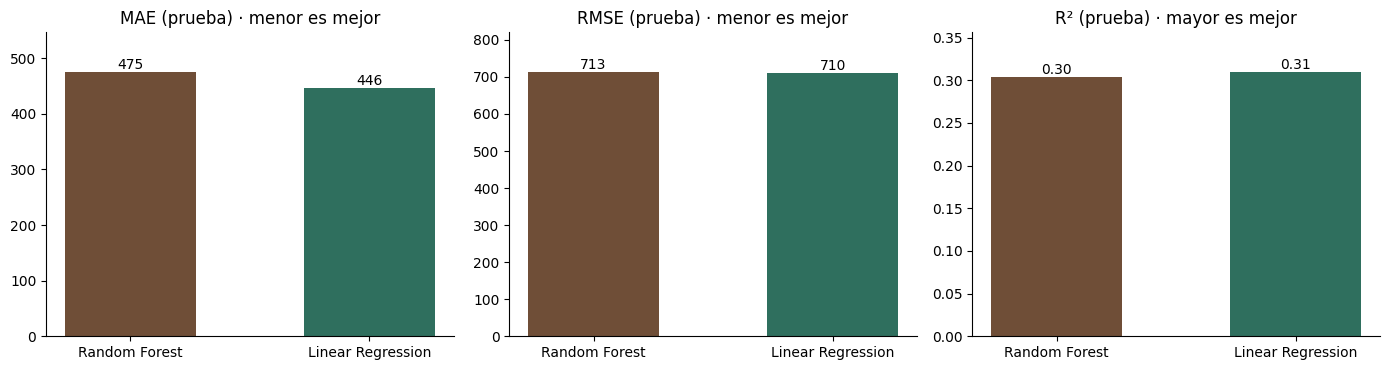

In [19]:
modelos = crear_modelos(busqueda.best_params_)
resultados_modelos = {nombre: entrenar_y_evaluar(m, X_train, y_train, X_test, y_test) for nombre, m in modelos.items()}
assert np.isclose(resultados_modelos[RF]["MAE"], m_rf["MAE"])        # coincide con la evaluación anterior

tabla_comparativa, mejores = comparar_modelos(resultados_modelos)
display(tabla_comparativa.round({"MAE": 1, "RMSE": 1, "R²": 3, "Entrenamiento (s)": 4, "Predicción (ms)": 3}))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, metrica in zip(axes, ["MAE", "RMSE", "R²"]):
    valores = tabla_comparativa[metrica]
    ax.bar(valores.index, valores.values, color=[COLORES_MODELO[m] for m in valores.index], width=.55)
    for i, v in enumerate(valores.values):
        ax.text(i, v, f"{v:,.2f}" if metrica == "R²" else f"{v:,.0f}", ha="center", va="bottom", fontsize=10)
    ax.set(title=f"{metrica} (prueba)" + (" · menor es mejor" if metrica != "R²" else " · mayor es mejor"))
    ax.margins(y=.15)
plt.tight_layout(); plt.show()

In [20]:
# Estabilidad temporal, orden de los cafés y evidencia estadística
mae_cv = validacion_temporal(modelos, X_train, y_train, separacion)
test_cmp = test.assign(pred_rf=resultados_modelos[RF]["pred"], pred_lr=resultados_modelos[LR]["pred"])
ranking_modelos = pd.DataFrame({RF: evaluar_ranking(test_cmp, "pred_rf"), LR: evaluar_ranking(test_cmp, "pred_lr")}).T
dif_mae, ic_mae = bootstrap_diferencia_mae(test_cmp, "pred_rf", "pred_lr")

display(mae_cv.round(1))
display(ranking_modelos.round(2))
print(f"Diferencia de MAE en prueba (Random Forest - Linear Regression): {dif_mae:,.1f} | IC 95 %: [{ic_mae[0]:,.1f}; {ic_mae[1]:,.1f}]")

,filas_entrenamiento,Random Forest,Linear Regression
pliegue,,,
1,16,456.5,335.2
2,68,318.7,1798.7
3,120,481.6,587.7
4,172,454.7,631.2


,Spearman,Top 1,Top 3
Random Forest,0.77,0.3,0.7
Linear Regression,0.69,0.1,0.6


Diferencia de MAE en prueba (Random Forest - Linear Regression): 29.1 | IC 95 %: [-12.7; 71.0]


In [21]:
rf, lr = resultados_modelos[RF], resultados_modelos[LR]
pliegues_rf = int((mae_cv[RF] < mae_cv[LR]).sum())
incluye_cero = ic_mae[0] <= 0 <= ic_mae[1]
display(Markdown(f'''
- **Error en prueba:** {mejores["MAE"]} tiene el menor MAE ({es(tabla_comparativa.loc[mejores["MAE"], "MAE"])} frente a {es(tabla_comparativa.loc[otro(mejores["MAE"]), "MAE"])}); en RMSE ({es(rf["RMSE"])} frente a {es(lr["RMSE"])}) y R² ({es(rf["R²"], 2)} frente a {es(lr["R²"], 2)}) {"la diferencia es mínima" if abs(rf["R²"] - lr["R²"]) < 0.05 else "hay una diferencia relevante"}.
- **Evidencia estadística:** el IC 95 % de la diferencia de MAE (Random Forest − Linear Regression) es [{es(ic_mae[0])}; {es(ic_mae[1])}], que {"incluye el cero: con " + str(test["fecha_ref"].nunique()) + " fechas de prueba la diferencia no es estadísticamente distinguible" if incluye_cero else "no incluye el cero: la diferencia es estadísticamente distinguible"}.
- **Estabilidad temporal:** el Random Forest tiene menor error en {pliegues_rf} de {len(mae_cv)} pliegues; MAE medio de validación {es(mae_cv[RF].mean())} frente a {es(mae_cv[LR].mean())}, y peor pliegue {es(mae_cv[RF].max())} frente a {es(mae_cv[LR].max())}.
- **Orden de los cafés:** Spearman medio {es(ranking_modelos.loc[RF, "Spearman"], 2)} frente a {es(ranking_modelos.loc[LR, "Spearman"], 2)}; acierto del café #1 {es(ranking_modelos.loc[RF, "Top 1"], 0, True)} frente a {es(ranking_modelos.loc[LR, "Top 1"], 0, True)} y del top 3 {es(ranking_modelos.loc[RF, "Top 3"], 0, True)} frente a {es(ranking_modelos.loc[LR, "Top 3"], 0, True)}.
- **Tiempos:** entrenamiento {es(rf["t_entrenamiento"], 3)} s frente a {es(lr["t_entrenamiento"], 3)} s; predicción {es(rf["t_prediccion"] * 1000, 1)} ms frente a {es(lr["t_prediccion"] * 1000, 1)} ms. Ambos son despreciables para predecir ocho cafés una vez por mes.
'''))


- **Error en prueba:** Linear Regression tiene el menor MAE (446 frente a 475); en RMSE (713 frente a 710) y R² (0,30 frente a 0,31) la diferencia es mínima.
- **Evidencia estadística:** el IC 95 % de la diferencia de MAE (Random Forest − Linear Regression) es [-13; 71], que incluye el cero: con 10 fechas de prueba la diferencia no es estadísticamente distinguible.
- **Estabilidad temporal:** el Random Forest tiene menor error en 3 de 4 pliegues; MAE medio de validación 428 frente a 838, y peor pliegue 482 frente a 1.799.
- **Orden de los cafés:** Spearman medio 0,77 frente a 0,69; acierto del café #1 30 % frente a 10 % y del top 3 70 % frente a 60 %.
- **Tiempos:** entrenamiento 0,165 s frente a 0,002 s; predicción 39,2 ms frente a 1,0 ms. Ambos son despreciables para predecir ocho cafés una vez por mes.


## Selección del Modelo Final

La decisión combina tres criterios que reflejan lo que necesita el usuario: **error en prueba** (mayoría entre MAE, RMSE y R²), **robustez temporal** (pliegues ganados) y **orden de los cafés** (Spearman), porque la pregunta pide identificar cuál café priorizar. Se recomienda el modelo que gane más criterios; si empatan, el de predicción más rápida. Los tiempos no cuentan como criterio porque ambos son despreciables a esta escala.

In [22]:
votos = construir_votos(tabla_comparativa, mae_cv, ranking_modelos)
recomendado, conteo = recomendar_modelo(votos, desempate=mejores["Predicción (ms)"])
mas_preciso, menor_error = mejores["R²"], mejores["MAE"]

display(pd.DataFrame({"Criterio": list(votos), "Ganador": list(votos.values())}).set_index("Criterio"))
print(f"Modelo más preciso (R²): {mas_preciso} | modelo con menor error (MAE): {menor_error} | recomendado para producción: {recomendado}")
print(f"Si el único criterio fuera el error en prueba, el modelo elegido sería: {votos['Error en prueba']}")

criterios_ganados = [c.lower() for c, g in votos.items() if g == recomendado]
motivo = (f"{recomendado} gana {conteo[recomendado]} de {len(votos)} criterios ({', '.join(criterios_ganados)}). "
          + ("Es más estable entre períodos y ordena mejor los cafés, que es lo que exige la pregunta de negocio; "
             f"su costo de cómputo ({es(resultados_modelos[recomendado]['t_prediccion'] * 1000, 1)} ms por predicción) es irrelevante para ocho cafés al mes."
             if recomendado == RF else
             "Es más simple, rápido e interpretable, y la evidencia no justifica la complejidad del bosque."))

lider_prueba = votos["Error en prueba"]
conclusion_modelos = (
    f"**{lider_prueba}** predice marginalmente mejor en el período de prueba (MAE {es(tabla_comparativa.loc[lider_prueba, 'MAE'])} frente a "
    f"{es(tabla_comparativa.loc[otro(lider_prueba), 'MAE'])}), pero la diferencia "
    f"{'no es estadísticamente distinguible (el IC 95 % de la diferencia de MAE, [' + es(ic_mae[0]) + '; ' + es(ic_mae[1]) + '], incluye el cero)' if incluye_cero else 'es estadísticamente distinguible (el IC 95 % no incluye el cero)'}. "
    f"En robustez temporal gana {votos['Robustez temporal']} ({pliegues_rf if votos['Robustez temporal'] == RF else len(mae_cv) - pliegues_rf} de {len(mae_cv)} pliegues; "
    f"MAE medio de validación {es(mae_cv[RF].mean())} frente a {es(mae_cv[LR].mean())}) y en el orden de los cafés gana {votos['Orden de los cafés']} "
    f"(Spearman {es(ranking_modelos.loc[RF, 'Spearman'], 2)} frente a {es(ranking_modelos.loc[LR, 'Spearman'], 2)}). "
    f"La cafetería utilizará **{recomendado}**"
    + (": responde mejor a la pregunta de negocio, que exige ordenar los cafés de forma confiable, y su mayor tiempo de cómputo es irrelevante a esta escala. "
       "La regresión lineal queda como modelo de referencia." if recomendado == RF else
       ": la evidencia favorece al modelo lineal, por lo que el Random Forest debería reevaluarse con más historia.")
)
display(Markdown(f"**Modelo final recomendado: {recomendado}.** {motivo}"))
display(Markdown(conclusion_modelos))

,Ganador
Criterio,
Error en prueba,Linear Regression
Robustez temporal,Random Forest
Orden de los cafés,Random Forest


Modelo más preciso (R²): Linear Regression | modelo con menor error (MAE): Linear Regression | recomendado para producción: Random Forest
Si el único criterio fuera el error en prueba, el modelo elegido sería: Linear Regression


**Modelo final recomendado: Random Forest.** Random Forest gana 2 de 3 criterios (robustez temporal, orden de los cafés). Es más estable entre períodos y ordena mejor los cafés, que es lo que exige la pregunta de negocio; su costo de cómputo (39,2 ms por predicción) es irrelevante para ocho cafés al mes.

**Linear Regression** predice marginalmente mejor en el período de prueba (MAE 446 frente a 475), pero la diferencia no es estadísticamente distinguible (el IC 95 % de la diferencia de MAE, [-13; 71], incluye el cero). En robustez temporal gana Random Forest (3 de 4 pliegues; MAE medio de validación 428 frente a 838) y en el orden de los cafés gana Random Forest (Spearman 0,77 frente a 0,69). La cafetería utilizará **Random Forest**: responde mejor a la pregunta de negocio, que exige ordenar los cafés de forma confiable, y su mayor tiempo de cómputo es irrelevante a esta escala. La regresión lineal queda como modelo de referencia.

## Exportación

In [23]:
def cargar_artefactos(ruta=RUTA_MODELO):
    """Carga el modelo y el encoder guardados."""
    modelo = joblib.load(os.path.join(ruta, "modelo.joblib"))
    encoder = joblib.load(os.path.join(ruta, "encoder.joblib"))
    return modelo, encoder


def predecir_rentabilidad(ventas_nuevas, fecha_ref=None, ruta=RUTA_MODELO):
    """Ranking de rentabilidad esperada a HORIZONTE_DIAS desde `fecha_ref` (por defecto, el último día con datos).
    `ventas_nuevas` debe tener las columnas del dataset original."""
    modelo, encoder_guardado = cargar_artefactos(ruta)
    panel_nuevo = armar_panel_diario(preparar_ventas(ventas_nuevas))
    fecha_ref = pd.Timestamp(fecha_ref) if fecha_ref else panel_nuevo["ingresos"].index.max()
    tabla = armar_tabla_cafe(panel_nuevo, fecha_ref)
    matriz = armar_matriz(tabla, encoder_guardado).reindex(columns=modelo.feature_names_in_, fill_value=0)
    tabla["rentabilidad_estimada"] = modelo.predict(matriz)
    return tabla.sort_values("rentabilidad_estimada", ascending=False).reset_index(drop=True)


os.makedirs(RUTA_MODELO, exist_ok=True)
joblib.dump(modelo_final, os.path.join(RUTA_MODELO, "modelo.joblib"))
joblib.dump(encoder, os.path.join(RUTA_MODELO, "encoder.joblib"))

# Dataset procesado: lo usa modelo_linear_regression.ipynb
os.makedirs("datos", exist_ok=True)
pd.concat([dataset[["cafe", "fecha_ref", "y"]], X], axis=1).to_csv(os.path.join("datos", "dataset_procesado.csv"), index=False)

# Comprobación: el modelo recargado reproduce el ranking del notebook
recargado = predecir_rentabilidad(df)
assert np.allclose(recargado.set_index("cafe")["rentabilidad_estimada"].loc[ranking["cafe"]].to_numpy(),
                   ranking["rentabilidad_estimada"].to_numpy())
print("Archivos guardados en:", os.listdir(RUTA_MODELO), "y datos/dataset_procesado.csv")
display(recargado[["cafe", "rentabilidad_estimada"]].round(1))

Archivos guardados en: ['encoder.joblib', 'linear_regression_model.joblib', 'modelo.joblib', 'resultados.json'] y datos/dataset_procesado.csv


,cafe,rentabilidad_estimada
0,Americano,2810.5
1,Latte,2340.0
2,Americano with Milk,1569.1
3,Cappuccino,1353.7
4,Cocoa,1186.8
5,Hot Chocolate,979.5
6,Cortado,581.7
7,Espresso,278.4


### Datos para la aplicación web

Se generan los resultados que sirve la API (`modelo/resultados.json`): métricas, importancia, histórico, comparación de modelos, hallazgos y conclusiones redactados en este notebook. El ranking no se guarda: la API lo calcula en vivo con el modelo exportado a partir de `caracteristicas_hoy`.

In [24]:
redondear = lambda s, n=2: [round(float(v), n) for v in s]

hallazgos = [
    f"**{mas_rentable['cafe']}** lidera la rentabilidad esperada: {es(mas_rentable['rentabilidad_estimada'])} unidades monetarias ({es(mas_rentable['peso_total'], 1, True)} del total proyectado).",
    f"Los tres primeros cafés ({', '.join(ranking['cafe'].head(3))}) concentran el {es(peso_top3, 0, True)} de la rentabilidad proyectada.",
    f"El Random Forest {'reduce' if mejora_mae > 0 else 'aumenta'} el MAE en {es(abs(mejora_mae), 1, True)} frente a repetir el mes anterior (R² {es(m_rf['R²'], 2)} frente a {es(m_base['R²'], 2)}).",
    f"El café realmente más rentable quedó entre los 3 primeros del modelo en el {es(rk_rf['Top 3'], 0, True)} de las fechas de prueba (modelo base: {es(rk_base['Top 3'], 0, True)}).",
    f"Variables más influyentes del modelo final: {', '.join(f'{v} ({es(p, 0, True)})' for v, p in imp_final.head(3).items())}; el modelo se apoya sobre todo en cuánto pesó cada café en las compras del último mes.",
    f"La ventaja del primer café sobre el segundo ({es(brecha)}) equivale a {es(holgura, 1)} veces el error típico ({es(m_rf['MAE'])}) y {'los rangos entre árboles se superponen' if solapan else 'los rangos entre árboles no se superponen'}.",
    f"El total proyectado ({es(total_proyectado)}) es {es(abs(variacion_total), 0, True)} {mayor_menor} que el de los últimos 30 días: el ranking es más confiable que el valor absoluto.",
    f"Frente a una regresión lineal, {recomendado} gana {conteo[recomendado]} de {len(votos)} criterios; en el error de prueba la diferencia con {otro(recomendado)} es mínima y {'no es' if incluye_cero else 'es'} estadísticamente distinguible.",
]

mensual = ventas.assign(mes=ventas["ts"].dt.to_period("M").astype(str)).pivot_table(
    index="mes", columns="coffee_name", values="money", aggfunc="sum", fill_value=0)

resultados = {
    "meta": {"fecha_ultimo_dato": str(fecha_fin.date()), "inicio_prediccion": str(inicio.date()), "fin_prediccion": str(fin.date()),
             "horizonte_dias": HORIZONTE_DIAS, "filas_archivo": int(len(df)), "filas_base": int(len(ventas)), "duplicados_base": int(duplicadas.sum()),
             "combinaciones": int(len(busqueda.cv_results_["params"])),
             "periodo": [str(ventas["fecha"].min().date()), str(ventas["fecha"].max().date())], "n_cafes": len(CAFES),
             "n_fechas_corte": int(len(fechas_corte)), "n_entrenamiento": int(len(X_train)), "n_prueba": int(len(X_test))},
    "parametros": {k: (None if v is None else int(v)) for k, v in busqueda.best_params_.items()},
    "mae_validacion_cruzada": round(float(-busqueda.best_score_), 2),
    "metricas": {"rf": {k: round(float(v), 4) for k, v in m_rf.items()}, "base": {k: round(float(v), 4) for k, v in m_base.items()},
                 "entrenamiento": {k: round(float(v), 4) for k, v in m_train.items()},
                 "ranking_rf": {k: round(float(v), 4) for k, v in rk_rf.items()},
                 "ranking_base": {k: round(float(v), 4) for k, v in rk_base.items()}, "mejora_mae": round(float(mejora_mae), 4)},
    "importancia": {"final": [{"variable": v, "valor": round(float(p), 4)} for v, p in imp_final.items()],
                    "interna": [{"variable": v, "valor": round(float(p), 4)} for v, p in imp_interna.items()],
                    "permutacion": [{"variable": v, "valor": round(float(p), 2)} for v, p in imp_perm.items()]},
    "caracteristicas_hoy": [{"cafe": r["cafe"], **{v: float(r[v]) for v in VARIABLES_NUMERICAS}} for _, r in tabla_hoy.iterrows()],
    "historico": {"meses": list(mensual.index), "series": {c: redondear(mensual[c], 1) for c in mensual.columns}},
    "prueba": {"puntos": [{"cafe": r["cafe"], "fecha": str(r["fecha_ref"].date()), "real": round(float(r["y"]), 1),
                           "rf": round(float(r["pred_rf"]), 1), "base": round(float(r["pred_base"]), 1)} for _, r in test.iterrows()],
               "totales": {"fechas": [str(f.date()) for f in por_fecha.index], "real": redondear(por_fecha["y"], 1),
                           "rf": redondear(por_fecha["pred_rf"], 1), "base": redondear(por_fecha["pred_base"], 1)}},
    "comparacion": {
        "modelos": [RF, LR],
        "metricas": {n: {"MAE": round(float(r["MAE"]), 2), "RMSE": round(float(r["RMSE"]), 2), "R2": round(float(r["R²"]), 4),
                         "t_entrenamiento_s": round(float(r["t_entrenamiento"]), 4), "t_prediccion_ms": round(float(r["t_prediccion"] * 1000), 3),
                         **{k: round(float(v), 4) for k, v in ranking_modelos.loc[n].items()}}
                     for n, r in resultados_modelos.items()},
        "mejores": dict(mejores),
        "cv": {"pliegues": [int(i) for i in mae_cv.index], "filas_entrenamiento": [int(v) for v in mae_cv["filas_entrenamiento"]],
               RF: redondear(mae_cv[RF], 1), LR: redondear(mae_cv[LR], 1)},
        "votos": [{"criterio": c, "ganador": g} for c, g in votos.items()],
        "bootstrap": {"diferencia_mae": round(float(dif_mae), 2), "ic95": [round(float(v), 2) for v in ic_mae]},
        "mas_preciso": mas_preciso, "menor_error": menor_error, "recomendado": recomendado,
        "motivo": motivo, "conclusion": conclusion_modelos,
    },
    "hallazgos": hallazgos,
    "conclusiones": [parrafo_1, parrafo_2, conclusion_modelos],
}
ruta_resultados = os.path.join(RUTA_MODELO, "resultados.json")
with open(ruta_resultados, "w", encoding="utf-8") as f:
    json.dump(resultados, f, ensure_ascii=False, indent=1)

print(f"{ruta_resultados} generado ({os.path.getsize(ruta_resultados) // 1024} KB)")
display(Markdown("\n".join(f"- {h}" for h in hallazgos)))

modelo\resultados.json generado (23 KB)


- **Americano** lidera la rentabilidad esperada: 2.810 unidades monetarias (25,3 % del total proyectado).
- Los tres primeros cafés (Americano, Latte, Americano with Milk) concentran el 61 % de la rentabilidad proyectada.
- El Random Forest reduce el MAE en 3,5 % frente a repetir el mes anterior (R² 0,30 frente a 0,26).
- El café realmente más rentable quedó entre los 3 primeros del modelo en el 70 % de las fechas de prueba (modelo base: 70 %).
- Variables más influyentes del modelo final: participacion_30d (38 %), ingresos_30d (34 %), ingresos_7d (7 %); el modelo se apoya sobre todo en cuánto pesó cada café en las compras del último mes.
- La ventaja del primer café sobre el segundo (471) equivale a 1,0 veces el error típico (475) y los rangos entre árboles se superponen.
- El total proyectado (11.100) es 15 % menor que el de los últimos 30 días: el ranking es más confiable que el valor absoluto.
- Frente a una regresión lineal, Random Forest gana 2 de 3 criterios; en el error de prueba la diferencia con Linear Regression es mínima y no es estadísticamente distinguible.